# 🛡️ Multi-Agent Cyber-Threat Detection and Response System Using CrewAI and RAG

**Author:** Shreya Singh · B.Tech CSE (AI), Manipal Institute of Technology, Bengaluru · Agentic AI course project (October 2026)

> **Scope note.** This is an educational demo. All log events are **synthetic** (generated in this notebook with a fixed seed),
> the knowledge base is a small hand-written summary of MITRE ATT&CK techniques and response playbooks, and the agents only
> **recommend** actions — nothing is blocked, isolated or remediated. Any "compromise" in the outputs refers to the simulated scenario.

---

## 1. Problem Statement
Security Operations Centres (SOCs) receive thousands of log events every hour. Human analysts must
(1) spot the malicious events, (2) understand what kind of attack they are, (3) decide how to respond,
and (4) write an incident report. This is slow, repetitive and error-prone.

**Goal:** build a team of cooperating AI agents that automates this SOC workflow end to end:

| Step | Agent | What it does |
|---|---|---|
| 1 | 🔍 **Log Analyst** | Runs a detection engine over security logs and confirms real threats |
| 2 | 📚 **Threat Intelligence Analyst** | Uses **RAG** over a threat knowledge base to map each threat to MITRE ATT&CK |
| 3 | 🚨 **Incident Responder** | Retrieves response playbooks (RAG) and builds a prioritised containment plan |
| 4 | 📝 **SOC Report Writer** | Produces a professional incident report for management |

## 2. Architecture

```
 Security logs (CSV) ──► Rule-based Detection Engine ──► [Tool] analyze_security_logs
                                                                │
 Threat KB (MITRE ATT&CK + playbooks) ──► Embeddings ──► FAISS ──► [Tool] search_threat_intel   (RAG)
                                                                │
        ┌──────────────── CrewAI (sequential process, Gemini LLM) ────────────────┐
        │  Log Analyst ──► Threat Intel Analyst ──► Incident Responder ──► Writer │
        └──────────────────────────────────────────────────────────────────────────┘
                                                                │
                                              Final SOC Incident Report (Markdown)
```

**Tech stack:** CrewAI (multi-agent orchestration) · Google Gemini (LLM) · Sentence-Transformers (embeddings) ·
FAISS (vector store) · Pandas / Matplotlib (data + visuals)

## 3. Setup
### 3.1 Install libraries


In [29]:
!pip install -q crewai google-genai litellm faiss-cpu sentence-transformers

### 3.2 Verify Installed Libraries

In [30]:
from crewai import Agent, Task, Crew, Process, LLM
from crewai.tools import tool
from google import genai
from sentence_transformers import SentenceTransformer
import faiss, pandas, sklearn, matplotlib
from importlib.metadata import version

for pkg in ["crewai", "google-genai", "litellm", "faiss-cpu", "sentence-transformers", "pandas", "scikit-learn"]:
    try:
        print(f"{pkg:22s} {version(pkg)}")
    except Exception:
        print(f"{pkg:22s} (not found)")
print("✅ All libraries import successfully. Continue to the API key cell.")

crewai                 1.15.28
google-genai           2.12.1
litellm                1.106.1
faiss-cpu              1.15.1
sentence-transformers  5.7.0
pandas                 2.2.3
scikit-learn           1.6.1
✅ All libraries import successfully. Continue to the API key cell.


### 3.3 Connect to Gemini


In [31]:
import os

# Read the key from Colab Secrets (key icon in the left sidebar). It is never printed or saved in the notebook.
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:          # running outside Colab: fall back to an environment variable
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Add GEMINI_API_KEY in Colab Secrets and enable Notebook access.")

os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY
os.environ.pop("GOOGLE_API_KEY", None)
os.environ["CREWAI_TELEMETRY_OPT_OUT"] = "true"
print("✅ Gemini API key loaded from Colab Secrets")

# Gemini model IDs change over time; try current Flash models and keep the first that answers.
# Free-tier quota is counted per model per day. If one model's daily quota is used up, the loop moves on to the next.
CANDIDATE_MODELS = [
    "gemini/gemini-3.5-flash-lite",
    "gemini/gemini-3.5-flash",
    "gemini/gemini-3.6-flash",
    "gemini/gemini-3.1-flash-lite",
]
llm, MODEL_NAME = None, None
for candidate in CANDIDATE_MODELS:
    try:
        test_llm = LLM(model=candidate, api_key=GEMINI_API_KEY, temperature=0.2)
        test_llm.call("Reply with exactly: OK")
        llm, MODEL_NAME = test_llm, candidate
        print(f"✅ Using {MODEL_NAME}")
        break
    except Exception as exc:
        print(f"❌ {candidate} unavailable: {type(exc).__name__}")

assert llm is not None, "No Gemini model responded. Check the key and quota in Google AI Studio."

✅ Gemini API key loaded from Colab Secrets
✅ Using gemini/gemini-3.5-flash-lite


In [32]:
# Optional helper: list the Flash models this key can see (listing does not use generation quota).
from google import genai
client = genai.Client(api_key=GEMINI_API_KEY)
for m in client.models.list():
    if "flash" in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


## 4. Dataset – Simulated Enterprise Security Logs
Real SOC logs are confidential, so we generate a **synthetic log dataset** with a fixed random seed
(fully reproducible). It mixes normal traffic with **7 attack scenarios**, and every row carries a ground-truth
`label` so we can measure detection accuracy.

| Attack | MITRE ID | Simulated behaviour |
|---|---|---|
| SSH brute force (+ successful login) | T1110 | 45 failed logins on `admin`, then a success |
| Port scan | T1046 | One IP probing 60 different ports |
| SQL injection | T1190 | Malicious payloads in web requests |
| C2 beaconing | T1071 | Infected host calling out every 60 s to port 4444 |
| Data exfiltration | T1048 | Very large outbound transfers |
| Privilege escalation | T1068 | Low-privilege user gaining root |
| Phishing link click | T1566 | User visiting a look-alike credential page |

In [33]:
import random
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

random.seed(42); np.random.seed(42)
BASE = datetime(2026, 10, 20, 9, 0, 0)
rows = []

def add(t, src, dst, port, user, event, status, bytes_out, payload, label):
    rows.append(dict(timestamp=BASE + timedelta(seconds=t), src_ip=src, dst_ip=dst, dst_port=port,
                     user=user, event_type=event, status=status, bytes_out=bytes_out,
                     payload=payload, label=label))

internal_hosts = [f"10.0.0.{i}" for i in range(10, 40)]
staff = ["arjun", "meera", "rahul", "priya", "kiran", "sneha", "vikram", "anita"]
web_paths = ["/home", "/products", "/login", "/cart", "/api/items?id=12", "/about", "/search?q=laptop"]

# --- Normal traffic (benign) ---
for _ in range(300):
    t = random.randint(0, 3600)
    kind = random.choice(["login", "web", "web", "dns", "file"])
    host = random.choice(internal_hosts)
    if kind == "login":
        ok = random.random() > 0.08            # occasional typo = failed login (benign)
        add(t, host, "10.0.0.5", 22, random.choice(staff), "auth", "success" if ok else "failure", 0, "", "benign")
    elif kind == "web":
        add(t, f"49.36.{random.randint(1,250)}.{random.randint(1,250)}", "10.0.0.80", 443, "-", "http_request",
            "200", random.randint(500, 9000), "GET " + random.choice(web_paths), "benign")
    elif kind == "dns":
        add(t, host, "8.8.8.8", 53, "-", "dns_query", "ok", 120, random.choice(["google.com", "office.com", "github.com"]), "benign")
    else:
        add(t, host, "10.0.0.60", 445, random.choice(staff), "file_access", "ok", random.randint(1_000, 2_000_000), "\\\\fileserver\\shared", "benign")

# --- Attack 1: SSH brute force then success ---
for i in range(45):
    add(600 + i * 3, "185.220.101.45", "10.0.0.5", 22, "admin", "auth", "failure", 0, "", "brute_force")
add(600 + 45 * 3 + 2, "185.220.101.45", "10.0.0.5", 22, "admin", "auth", "success", 0, "", "brute_force")

# --- Attack 2: Port scan ---
for i, p in enumerate(random.sample(range(20, 9000), 60)):
    add(1200 + i, "203.0.113.77", "10.0.0.80", p, "-", "connection", "rejected", 60, "SYN", "port_scan")

# --- Attack 3: SQL injection ---
sqli = ["GET /api/items?id=1' OR '1'='1", "GET /login?user=admin'--", "GET /api/items?id=1 UNION SELECT username,password FROM users",
        "GET /search?q='; DROP TABLE orders;--", "GET /api/items?id=1 AND SLEEP(5)"]
for i, p in enumerate(sqli * 2):
    add(1800 + i * 7, "91.240.118.22", "10.0.0.80", 443, "-", "http_request", random.choice(["500", "200", "403"]), 1500, p, "sql_injection")

# --- Attack 4: C2 beaconing from infected host ---
for i in range(30):
    add(900 + i * 60 + random.randint(-2, 2), "10.0.0.23", "45.33.32.156", 4444, "-", "connection", "established", 512, "beacon", "c2_beacon")

# --- Attack 5: Data exfiltration from the same infected host ---
for i in range(4):
    add(2900 + i * 40, "10.0.0.23", "45.33.32.156", 443, "-", "file_transfer", "ok", random.randint(250, 600) * 1_000_000, "archive.zip", "data_exfiltration")

# --- Attack 6: Privilege escalation ---
add(2400, "10.0.0.31", "10.0.0.31", 0, "intern01", "privilege_change", "failure", 0, "sudo su root", "privilege_escalation")
add(2410, "10.0.0.31", "10.0.0.31", 0, "intern01", "privilege_change", "failure", 0, "sudo su root", "privilege_escalation")
add(2425, "10.0.0.31", "10.0.0.31", 0, "intern01", "privilege_change", "success", 0, "exploit CVE-2021-4034 -> uid=0(root)", "privilege_escalation")

# --- Attack 7: Phishing link click ---
add(500, "10.0.0.17", "104.21.55.9", 443, "meera", "http_request", "200", 3200, "GET http://micros0ft-login-verify.com/office365/signin", "phishing")
add(505, "10.0.0.17", "104.21.55.9", 443, "meera", "http_request", "200", 900, "POST http://micros0ft-login-verify.com/office365/submit", "phishing")

logs = pd.DataFrame(rows).sort_values("timestamp").reset_index(drop=True)
logs.to_csv("security_logs.csv", index=False)

print(f"Total events: {len(logs)}")
print(logs["label"].value_counts().to_string())
logs.sample(8, random_state=1)

Total events: 455
label
benign                  300
port_scan                60
brute_force              46
c2_beacon                30
sql_injection            10
data_exfiltration         4
privilege_escalation      3
phishing                  2


,timestamp,src_ip,dst_ip,dst_port,user,event_type,status,bytes_out,payload,label
67,2026-10-20 09:10:51,185.220.101.45,10.0.0.5,22,admin,auth,failure,0,,brute_force
146,2026-10-20 09:20:00,203.0.113.77,10.0.0.80,450,-,connection,rejected,60,SYN,port_scan
322,2026-10-20 09:39:17,49.36.179.99,10.0.0.80,443,-,http_request,200,8599,GET /cart,benign
250,2026-10-20 09:29:06,10.0.0.25,10.0.0.5,22,anita,auth,success,0,,benign
223,2026-10-20 09:24:01,10.0.0.23,45.33.32.156,4444,-,connection,established,512,beacon,c2_beacon
366,2026-10-20 09:45:02,10.0.0.27,8.8.8.8,53,-,dns_query,ok,120,google.com,benign
380,2026-10-20 09:46:55,49.36.68.202,10.0.0.80,443,-,http_request,200,3741,GET /cart,benign
426,2026-10-20 09:54:55,10.0.0.21,10.0.0.60,445,meera,file_access,ok,1659180,\\fileserver\shared,benign


## 5. Rule-Based Detection Engine
LLMs are not reliable at counting thousands of rows, so the **numerical detection is done by deterministic Python rules**
(like a real SIEM). The agents then *reason* over the detections. This hybrid design is a key point of the project:
**rules give precision and repeatability, agents give context, explanation and decisions.**

In [34]:
import re, json, warnings
warnings.filterwarnings("ignore")

SQLI_PATTERNS = re.compile(r"('\s*or\s*'?1'?\s*=\s*'?1)|(union\s+select)|(drop\s+table)|(--)|(sleep\s*\()", re.I)
SUSPICIOUS_DOMAIN = re.compile(r"(micros0ft|paypa1|g00gle|-login-|verify-account|secure-update)", re.I)
TRUSTED_EXTERNAL = {"8.8.8.8"}

def is_internal(ip): return str(ip).startswith("10.")

def detect_threats(df: pd.DataFrame) -> list:
    detections = []

    # R1 – Brute force: >= 10 failed logins from one IP within 5 minutes
    fails = df[(df.event_type == "auth") & (df.status == "failure")]
    for ip, g in fails.groupby("src_ip"):
        g = g.sort_values("timestamp")
        window = g.set_index("timestamp").rolling("5min")["dst_port"].count()
        if window.max() >= 10:
            succ = df[(df.src_ip == ip) & (df.event_type == "auth") & (df.status == "success")]
            compromised = len(succ) > 0
            detections.append(dict(threat="Brute Force Attack", rule="R1", severity="CRITICAL" if compromised else "HIGH",
                source=ip, target=", ".join(g.dst_ip.unique()), count=int(len(g)),
                first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
                evidence=f"{len(g)} failed logins for user(s) {list(g.user.unique())}; "
                         + ("followed by a successful login from the same IP (possible account compromise – needs verification)" if compromised else "no successful login"),
                rows=list(g.index) + list(succ.index)))

    # R2 – Port scan: one source touching >= 20 distinct ports
    conns = df[df.event_type == "connection"]
    for ip, g in conns.groupby("src_ip"):
        if g.dst_port.nunique() >= 20:
            detections.append(dict(threat="Port Scanning / Reconnaissance", rule="R2", severity="MEDIUM",
                source=ip, target=", ".join(g.dst_ip.unique()), count=int(len(g)),
                first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
                evidence=f"{g.dst_port.nunique()} distinct ports probed in {(g.timestamp.max()-g.timestamp.min()).seconds}s",
                rows=list(g.index)))

    # R3 – SQL injection signatures in HTTP payloads
    sq = df[(df.event_type == "http_request") & df.payload.str.contains(SQLI_PATTERNS, na=False)]
    for ip, g in sq.groupby("src_ip"):
        detections.append(dict(threat="SQL Injection Attempt", rule="R3", severity="HIGH",
            source=ip, target=", ".join(g.dst_ip.unique()), count=int(len(g)),
            first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
            evidence=f"Payload samples: {list(g.payload.unique()[:3])}; HTTP codes {list(g.status.unique())}",
            rows=list(g.index)))

    # R4 – C2 beaconing: internal->external connections at very regular intervals
    out = conns[conns.src_ip.map(is_internal) & ~conns.dst_ip.map(is_internal)]
    for (src, dst, port), g in out.groupby(["src_ip", "dst_ip", "dst_port"]):
        if len(g) >= 10:
            gaps = g.timestamp.sort_values().diff().dt.total_seconds().dropna()
            if gaps.std() < 5:
                detections.append(dict(threat="Command & Control Beaconing", rule="R4", severity="CRITICAL",
                    source=src, target=f"{dst}:{port}", count=int(len(g)),
                    first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
                    evidence=f"{len(g)} outbound connections every ~{gaps.mean():.0f}s (std {gaps.std():.1f}s) to non-standard port {port}",
                    rows=list(g.index)))

    # R5 – Data exfiltration: > 100 MB to an external IP in one transfer
    big = df[(df.bytes_out > 100_000_000) & ~df.dst_ip.map(is_internal) & ~df.dst_ip.isin(TRUSTED_EXTERNAL)]
    for (src, dst), g in big.groupby(["src_ip", "dst_ip"]):
        detections.append(dict(threat="Data Exfiltration", rule="R5", severity="CRITICAL",
            source=src, target=dst, count=int(len(g)),
            first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
            evidence=f"{g.bytes_out.sum()/1e9:.2f} GB sent externally in {len(g)} transfers ({list(g.payload.unique())})",
            rows=list(g.index)))

    # R6 – Privilege escalation: privilege change by a non-admin account
    pe = df[(df.event_type == "privilege_change") & (df.user != "admin")]
    for user, g in pe.groupby("user"):
        ok = (g.status == "success").any()
        detections.append(dict(threat="Privilege Escalation", rule="R6", severity="CRITICAL" if ok else "MEDIUM",
            source=f"{g.src_ip.iloc[0]} (user {user})", target="root", count=int(len(g)),
            first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
            evidence=f"Commands: {list(g.payload.unique())}; succeeded={ok}", rows=list(g.index)))

    # R7 – Phishing: access to look-alike / credential-harvesting domains
    ph = df[(df.event_type == "http_request") & df.payload.str.contains(SUSPICIOUS_DOMAIN, na=False)]
    for (src, user), g in ph.groupby(["src_ip", "user"]):
        submitted = g.payload.str.startswith("POST").any()
        detections.append(dict(threat="Phishing / Credential Harvesting", rule="R7", severity="HIGH" if submitted else "MEDIUM",
            source=f"{src} (user {user})", target=", ".join(g.dst_ip.unique()), count=int(len(g)),
            first_seen=str(g.timestamp.min()), last_seen=str(g.timestamp.max()),
            evidence=f"Visited look-alike domain; form POST observed={submitted} (contents unknown); {list(g.payload.unique())}",
            rows=list(g.index)))

    order = {"CRITICAL": 0, "HIGH": 1, "MEDIUM": 2, "LOW": 3}
    return sorted(detections, key=lambda d: order[d["severity"]])

DETECTIONS = detect_threats(logs)
det_df = pd.DataFrame(DETECTIONS).drop(columns=["rows"])
det_df[["severity", "threat", "source", "target", "count", "evidence"]]

,severity,threat,source,target,count,evidence
0,CRITICAL,Brute Force Attack,185.220.101.45,10.0.0.5,45,45 failed logins for user(s) ['admin']; follow...
1,CRITICAL,Command & Control Beaconing,10.0.0.23,45.33.32.156:4444,30,30 outbound connections every ~60s (std 2.3s) ...
2,CRITICAL,Data Exfiltration,10.0.0.23,45.33.32.156,4,2.00 GB sent externally in 4 transfers (['arch...
3,CRITICAL,Privilege Escalation,10.0.0.31 (user intern01),root,3,"Commands: ['sudo su root', 'exploit CVE-2021-4..."
4,HIGH,SQL Injection Attempt,91.240.118.22,10.0.0.80,10,"Payload samples: [""GET /api/items?id=1' OR '1'..."
5,HIGH,Phishing / Credential Harvesting,10.0.0.17 (user meera),104.21.55.9,2,Visited look-alike domain; form POST observed=...
6,MEDIUM,Port Scanning / Reconnaissance,203.0.113.77,10.0.0.80,60,60 distinct ports probed in 59s


### 5.1 Evaluating the detection engine
Because every row has a ground-truth label, we can compute **precision, recall and F1** at the event level.

In [35]:
from sklearn.metrics import classification_report, confusion_matrix

flagged = set(i for d in DETECTIONS for i in d["rows"])
y_true = (logs.label != "benign").astype(int)
y_pred = logs.index.isin(flagged).astype(int)

print(classification_report(y_true, y_pred, target_names=["benign", "malicious"], digits=3))
cm = confusion_matrix(y_true, y_pred)
print("Confusion matrix [[TN FP] [FN TP]]:\n", cm)

attack_types = sorted(set(logs.label) - {"benign"})
caught = {lbl: logs[(logs.label == lbl)].index.isin(flagged).mean() for lbl in attack_types}
print("\nPer-attack detection rate:")
for k, v in caught.items(): print(f"  {k:22s} {v*100:5.1f}%")

              precision    recall  f1-score   support

      benign      1.000     1.000     1.000       300
   malicious      1.000     1.000     1.000       155

    accuracy                          1.000       455
   macro avg      1.000     1.000     1.000       455
weighted avg      1.000     1.000     1.000       455

Confusion matrix [[TN FP] [FN TP]]:
 [[300   0]
 [  0 155]]

Per-attack detection rate:
  brute_force            100.0%
  c2_beacon              100.0%
  data_exfiltration      100.0%
  phishing               100.0%
  port_scan              100.0%
  privilege_escalation   100.0%
  sql_injection          100.0%


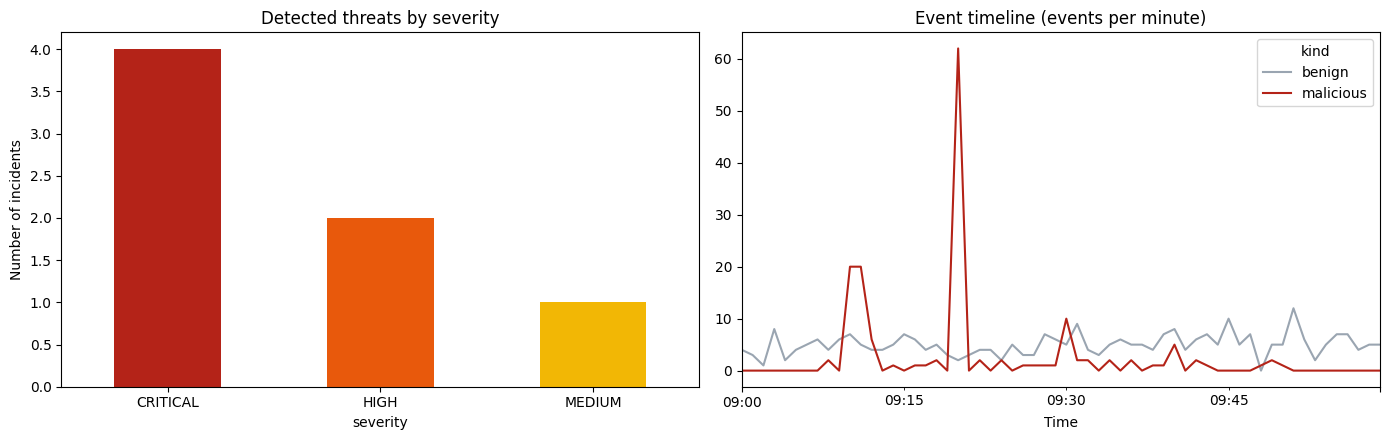

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sev_colors = {"CRITICAL": "#b42318", "HIGH": "#e8590c", "MEDIUM": "#f2b705", "LOW": "#2f9e44"}

det_df.groupby("severity").size().reindex(["CRITICAL", "HIGH", "MEDIUM"]).fillna(0).plot(
    kind="bar", ax=axes[0], color=[sev_colors[s] for s in ["CRITICAL", "HIGH", "MEDIUM"]])
axes[0].set_title("Detected threats by severity"); axes[0].set_ylabel("Number of incidents"); axes[0].tick_params(axis='x', rotation=0)

timeline = logs.copy(); timeline["minute"] = timeline.timestamp.dt.floor("min")
pivot = timeline.assign(kind=np.where(timeline.label == "benign", "benign", "malicious")).groupby(["minute", "kind"]).size().unstack(fill_value=0)
pivot.plot(ax=axes[1], color={"benign": "#9aa5b1", "malicious": "#b42318"})
axes[1].set_title("Event timeline (events per minute)"); axes[1].set_xlabel("Time")
plt.tight_layout(); plt.show()

## 6. RAG Knowledge Base – Threat Intelligence + Response Playbooks
**RAG (Retrieval-Augmented Generation):** instead of relying on what the LLM memorised, we store trusted security
knowledge in a **vector database** and retrieve the most relevant pieces at query time. This is intended to reduce hallucination
and lets the agents cite MITRE ATT&CK techniques and the organisation's own playbooks.

Pipeline: **documents → chunks → embeddings (all-MiniLM-L6-v2) → FAISS index → top-k similarity search**

In [37]:
THREAT_KB = [
 {"id": "T1110", "title": "Brute Force (MITRE ATT&CK T1110)", "tactic": "Credential Access",
  "text": "Adversaries repeatedly guess passwords to gain access to accounts. Sub-techniques include password guessing, "
          "password spraying and credential stuffing. Indicators: many failed authentications from one source in a short "
          "time, attempts against privileged accounts such as admin or root, logins from anonymising networks (Tor exit nodes). "
          "A successful login after many failures strongly suggests the account is compromised."},
 {"id": "PB-BF", "title": "Playbook: Brute Force / Account Compromise", "tactic": "Response",
  "text": "Containment: block the source IP at the firewall, disable or lock the targeted account, terminate its active sessions. "
          "Eradication: force a password reset, rotate SSH keys, review commands executed after the successful login. "
          "Recovery: enable multi-factor authentication, restrict SSH to VPN or bastion hosts, apply account lockout policy "
          "(for example 5 failures in 15 minutes) and deploy fail2ban. Severity is critical if a login succeeded."},
 {"id": "T1046", "title": "Network Service Discovery / Port Scanning (MITRE ATT&CK T1046)", "tactic": "Discovery / Reconnaissance",
  "text": "Adversaries scan ports to find running services and vulnerabilities before an attack. Indicators: one source "
          "connecting to dozens of different ports in seconds, many rejected or SYN-only connections. Scanning is often "
          "the first stage of the kill chain and frequently precedes exploitation attempts against discovered services."},
 {"id": "PB-PS", "title": "Playbook: Port Scan", "tactic": "Response",
  "text": "Block or rate-limit the scanning IP, check whether the same IP later attempted exploitation, verify only required "
          "ports are exposed, close unused services, and add the IP to threat-intel watchlists. Usually medium severity unless "
          "followed by exploitation."},
 {"id": "T1190", "title": "Exploit Public-Facing Application – SQL Injection (MITRE ATT&CK T1190)", "tactic": "Initial Access",
  "text": "Attackers send crafted input to web applications to manipulate database queries. Common payloads: ' OR '1'='1, "
          "UNION SELECT, DROP TABLE, comment sequences (--), and time-based SLEEP() probes. Impact can include authentication "
          "bypass, theft of user credentials and destruction of data. HTTP 500 responses may reveal vulnerable endpoints."},
 {"id": "PB-SQLI", "title": "Playbook: SQL Injection", "tactic": "Response",
  "text": "Block the attacking IP and enable Web Application Firewall SQL-injection rules. Review database logs for successful "
          "data access. Fix the code with parameterised queries / prepared statements, validate input, apply least-privilege "
          "database accounts, and run a vulnerability scan (e.g. OWASP ZAP). If data was read, start breach notification process."},
 {"id": "T1071", "title": "Application Layer Protocol – Command and Control Beaconing (MITRE ATT&CK T1071)", "tactic": "Command and Control",
  "text": "Malware on an infected host periodically 'beacons' to an attacker-controlled server to receive commands. Indicators: "
          "connections at highly regular intervals (for example every 60 seconds), small fixed-size packets, unusual destination "
          "ports such as 4444 (Metasploit default), and destinations with no business purpose. Beaconing means a host is already compromised."},
 {"id": "PB-C2", "title": "Playbook: Malware / C2 Infection", "tactic": "Response",
  "text": "Immediately isolate the infected host from the network (EDR network containment) while keeping it powered on for forensics. "
          "Block the C2 IP and domain at firewall and DNS. Capture memory and disk images, identify the malware family, hunt for the "
          "same indicators on other hosts, then re-image the machine and reset credentials used on it."},
 {"id": "T1048", "title": "Exfiltration Over Alternative Protocol (MITRE ATT&CK T1048)", "tactic": "Exfiltration",
  "text": "Adversaries steal data by transferring it to external servers, often compressed into archives (zip, rar) and sent over "
          "HTTPS or uncommon protocols. Indicators: unusually large outbound transfers, transfers to IPs already linked to C2, "
          "activity outside business hours. Exfiltration commonly follows a C2 infection on the same host."},
 {"id": "PB-EXF", "title": "Playbook: Data Exfiltration", "tactic": "Response",
  "text": "Block the destination, isolate the source host, and determine exactly which files were sent using file-server and DLP logs. "
          "Involve legal and compliance teams because data-protection laws (such as India's DPDP Act 2023 or GDPR) may require "
          "notification. Deploy Data Loss Prevention controls and egress filtering to prevent recurrence."},
 {"id": "T1068", "title": "Exploitation for Privilege Escalation (MITRE ATT&CK T1068)", "tactic": "Privilege Escalation",
  "text": "Attackers exploit software vulnerabilities to gain higher privileges such as root. Example: CVE-2021-4034 (PwnKit) in "
          "polkit pkexec gives local root on unpatched Linux systems. Indicators: failed sudo attempts by low-privilege users "
          "followed by sudden root access, execution of exploit binaries."},
 {"id": "PB-PE", "title": "Playbook: Privilege Escalation", "tactic": "Response",
  "text": "Disable the user account, isolate the host, review what was done with root privileges, check for persistence "
          "(new users, cron jobs, SSH keys). Patch the exploited vulnerability across all systems, enforce least privilege "
          "and monitor sudo usage centrally."},
 {"id": "T1566", "title": "Phishing (MITRE ATT&CK T1566)", "tactic": "Initial Access",
  "text": "Attackers trick users with emails linking to fake login pages on look-alike domains (for example micros0ft instead of "
          "microsoft). If the user submits credentials (an HTTP POST to the fake site), the attacker can log into real services. "
          "Phishing is the most common initial access vector in enterprise breaches."},
 {"id": "PB-PH", "title": "Playbook: Phishing / Credential Theft", "tactic": "Response",
  "text": "Reset the affected user's password and revoke active sessions and tokens, enforce MFA, block the phishing domain in "
          "DNS and email gateway, search mailboxes for the same phishing email and delete it, and give the user security "
          "awareness training. Check sign-in logs for logins from unusual locations."},
 {"id": "T1566.001", "title": "Phishing: Spearphishing Attachment (MITRE ATT&CK T1566.001)", "tactic": "Initial Access",
  "text": "Adversaries send emails with malicious attachments, often executables disguised with double extensions such as "
          "invoice.pdf.exe. Delivery or download of the attachment is evidence of attempted initial access; it does not by itself "
          "prove the file was opened or executed. Confirm with endpoint process logs or EDR telemetry."},
 {"id": "T1204.002", "title": "User Execution: Malicious File (MITRE ATT&CK T1204.002)", "tactic": "Execution",
  "text": "Adversaries rely on a user opening a malicious file. Evidence of execution includes process-creation events, "
          "EDR alerts or a parent-child process chain from the mail client or browser. Without such evidence, execution should "
          "be treated as a hypothesis, even if suspicious network activity follows a download."},
 {"id": "T1571", "title": "Non-Standard Port (MITRE ATT&CK T1571)", "tactic": "Command and Control",
  "text": "Adversaries may communicate over a port not normally associated with the protocol, such as 4444 or 8080, to evade "
          "filtering. Ports like 8080 are also widely used by legitimate web proxies, so port number alone is weak evidence. "
          "Application-layer protocol (T1071) should only be asserted when the protocol has been observed, for example in proxy or packet logs."},
 {"id": "T1041", "title": "Exfiltration Over C2 Channel (MITRE ATT&CK T1041)", "tactic": "Exfiltration",
  "text": "Adversaries may steal data over an existing command-and-control channel. If large transfers go to the same destination "
          "as earlier beaconing but on a different port or protocol, T1048 (alternative protocol) may fit better than T1041. "
          "Large byte counts alone do not establish what data was sent; file-level or DLP evidence is needed."},
 {"id": "SEV", "title": "Severity Classification Guide", "tactic": "Policy",
  "text": "CRITICAL: confirmed compromise or active data loss (successful intrusion, C2, exfiltration, root access) – respond within 15 minutes. "
          "HIGH: active attack likely to succeed or credentials exposed – respond within 1 hour. MEDIUM: reconnaissance or failed "
          "attempts – respond within 24 hours. LOW: informational."},
 {"id": "KILL", "title": "Cyber Kill Chain and Attack Correlation", "tactic": "Analysis",
  "text": "Attacks progress through stages: reconnaissance, initial access, execution, persistence, privilege escalation, command and "
          "control, and actions on objectives such as exfiltration. Analysts should correlate alerts that share a host or IP – for "
          "example C2 beaconing and large outbound transfers from the same host indicate one incident at an advanced stage."},
]
print(f"Knowledge base: {len(THREAT_KB)} documents")

Knowledge base: 20 documents


In [38]:
import faiss
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

# Chunking: each KB entry becomes one chunk (title + tactic + text); entries are short so no further splitting is needed
chunks = [f"{d['title']} | Tactic: {d['tactic']}\n{d['text']}" for d in THREAT_KB]
embeddings = embedder.encode(chunks, normalize_embeddings=True, show_progress_bar=False).astype("float32")

index = faiss.IndexFlatIP(embeddings.shape[1])   # inner product on normalised vectors = cosine similarity
index.add(embeddings)
print(f"FAISS index built: {index.ntotal} vectors × {embeddings.shape[1]} dimensions")

def retrieve(query: str, k: int = 3):
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k)
    return [(float(s), THREAT_KB[i]) for s, i in zip(scores[0], ids[0])]

# Quick retrieval test
for q in ["host contacting external server every minute on port 4444", "how to respond to sql injection"]:
    print(f"\n🔎 {q}")
    for s, d in retrieve(q):
        print(f"   {s:.3f}  {d['title']}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

FAISS index built: 20 vectors × 384 dimensions

🔎 host contacting external server every minute on port 4444
   0.326  Non-Standard Port (MITRE ATT&CK T1571)
   0.274  Application Layer Protocol – Command and Control Beaconing (MITRE ATT&CK T1071)
   0.251  Network Service Discovery / Port Scanning (MITRE ATT&CK T1046)

🔎 how to respond to sql injection
   0.580  Exploit Public-Facing Application – SQL Injection (MITRE ATT&CK T1190)
   0.542  Playbook: SQL Injection
   0.253  Severity Classification Guide


## 7. Agent Tools
CrewAI agents act through **tools**. We expose two:
* `analyze_security_logs` – runs the detection engine (gives agents facts, not guesses)
* `search_threat_intel` – the **RAG retriever** over the FAISS index

In [39]:
from crewai.tools import tool

@tool("analyze_security_logs")
def analyze_security_logs(filter_text: str = "all") -> str:
    '''Run the SIEM rule engine over the organisation's security logs and return detected threats as JSON.
    Input: 'all' for every detection, or a keyword (e.g. 'brute', 'sql', '10.0.0.23') to filter results.'''
    results = [{k: v for k, v in d.items() if k != "rows"} for d in DETECTIONS]
    f = (filter_text or "all").lower().strip()
    if f not in ("all", "", "none"):
        results = [d for d in results if f in json.dumps(d).lower()] or results
    summary = {"total_events_analyzed": len(logs), "time_range": f"{logs.timestamp.min()} to {logs.timestamp.max()}",
               "detections": results}
    return json.dumps(summary, indent=2, default=str)

@tool("search_threat_intel")
def search_threat_intel(query: str) -> str:
    '''Search the threat-intelligence knowledge base (MITRE ATT&CK techniques, response playbooks, severity policy)
    using semantic similarity. Input: a natural-language description of a threat or a question.'''
    hits = retrieve(query, k=3)
    return "\n\n".join(f"[{d['id']}] {d['title']} (tactic: {d['tactic']}, relevance {s:.2f})\n{d['text']}" for s, d in hits)

# Test the tools directly (no LLM involved)
print(analyze_security_logs.run("c2")[:600], "...\n")
print(search_threat_intel.run("account compromised after many failed ssh logins")[:500])

{
  "total_events_analyzed": 455,
  "time_range": "2026-10-20 09:00:13 to 2026-10-20 09:59:32",
  "detections": [
    {
      "threat": "Brute Force Attack",
      "rule": "R1",
      "severity": "CRITICAL",
      "source": "185.220.101.45",
      "target": "10.0.0.5",
      "count": 45,
      "first_seen": "2026-10-20 09:10:00",
      "last_seen": "2026-10-20 09:12:12",
      "evidence": "45 failed logins for user(s) ['admin']; followed by a successful login from the same IP (possible account compromise \u2013 needs verification)"
    },
    {
      "threat": "Command & Control Beaconing",
   ...

[PB-BF] Playbook: Brute Force / Account Compromise (tactic: Response, relevance 0.43)
Containment: block the source IP at the firewall, disable or lock the targeted account, terminate its active sessions. Eradication: force a password reset, rotate SSH keys, review commands executed after the successful login. Recovery: enable multi-factor authentication, restrict SSH to VPN or bastion hosts

## 8. Defining the Agents
Each CrewAI agent has a **role**, a **goal**, a **backstory** (persona that shapes its reasoning), an **LLM**, and **tools**.

In [40]:
log_analyst = Agent(
    role="Senior SOC Log Analyst",
    goal="Identify every genuine security threat in the organisation's logs, with exact evidence, affected assets and severity.",
    backstory="You are a tier-2 Security Operations Centre analyst with 8 years of experience triaging SIEM alerts. "
              "You never guess: you always run the log analysis tool and base every statement on its output. "
              "You also correlate alerts that share the same host or IP into a single incident.",
    tools=[analyze_security_logs], llm=llm, verbose=True, allow_delegation=False, max_iter=3,
)

threat_intel_analyst = Agent(
    role="Threat Intelligence Analyst",
    goal="Map each detected threat to the correct MITRE ATT&CK technique and tactic, and explain the attacker's likely objective.",
    backstory="You are a threat-intelligence specialist. You rely on the organisation's curated threat knowledge base "
              "(retrieved through the search tool) rather than memory, and you cite technique IDs such as T1110.",
    tools=[search_threat_intel], llm=llm, verbose=True, allow_delegation=False, max_iter=4,
)

incident_responder = Agent(
    role="Incident Response Lead",
    goal="Produce a prioritised, actionable containment, eradication and recovery plan for every incident.",
    backstory="You lead the Computer Security Incident Response Team (CSIRT). You follow the NIST SP 800-61 incident "
              "response lifecycle and the organisation's own playbooks, which you retrieve with the search tool. "
              "You prioritise by severity and response-time SLA.",
    tools=[search_threat_intel], llm=llm, verbose=True, allow_delegation=False, max_iter=4,
)

report_writer = Agent(
    role="SOC Report Writer",
    goal="Write a clear, well-structured incident report that both executives and engineers can act on.",
    backstory="You are a cyber-security communications specialist who turns technical findings into crisp reports "
              "with an executive summary, tables and clear next steps. You never invent facts not present in the inputs.",
    llm=llm, verbose=True, allow_delegation=False, max_iter=2,
)
# max_iter caps how many LLM round-trips each agent may use (keeps a full run within the free-tier daily quota)
print("✅ 4 agents created")

✅ 4 agents created


## 9. Defining the Pipeline Steps
Each step is one agent with one task. Steps run in order, and each step receives the outputs of the steps it depends on
(`deps`) — this is how the agents collaborate. Running each step separately means a failed step can be retried
without repeating the steps that already succeeded.

In [41]:
WINDOW = f"{logs.timestamp.min()} to {logs.timestamp.max()}"

EVIDENCE_RULES = (
    "IMPORTANT: These are SIMULATED lab logs, not a real organisation. Use only facts present in the tool outputs or earlier "
    "step outputs. Separate what the logs show from what is inferred: use words like 'indicates', 'suggests' or 'possible' for "
    "inferences. Do not claim confirmed compromise, malware execution, the sensitivity of transferred data, or a single "
    "coordinated attacker unless the evidence shows it. Do not say any action has been taken: all actions are recommendations. "
    "Mark a MITRE mapping as 'tentative' when the specific behaviour is not directly observed in the logs."
)

PIPELINE = [
    {"name": "detection", "label": "🔍 Log Analyst", "agent": log_analyst, "deps": [],
     "description": (f"Analyse the simulated security logs for the monitoring window {WINDOW}. Call the analyze_security_logs tool "
                     "once with input 'all'. For every detection, state its severity, source, target, and key evidence, and note "
                     "anything that still needs verification. Identify detections that share a host or IP and could be related. "
                     + EVIDENCE_RULES),
     "expected_output": "A numbered list of detections, each with: threat type, severity, source, target, evidence, open questions; "
                        "plus a short 'Possibly related detections' section."},

    {"name": "intel", "label": "📚 Threat Intel Analyst", "agent": threat_intel_analyst, "deps": ["detection"],
     "description": ("For each detection from the Log Analyst, use the search_threat_intel tool to identify the MITRE ATT&CK technique ID, "
                     "tactic and the attacker's likely objective. Call the tool at most 3 times in total; group related threats into "
                     "one query. Mark each mapping as 'direct' or 'tentative'. If the retrieved documents are not relevant, say so "
                     "instead of relying on memory. " + EVIDENCE_RULES),
     "expected_output": "A table: Threat | MITRE ID | Mapping confidence (direct/tentative) | Tactic | Likely objective, "
                        "followed by a 2–3 sentence assessment that distinguishes observed facts from hypotheses."},

    {"name": "response", "label": "🚨 Incident Responder", "agent": incident_responder, "deps": ["detection", "intel"],
     "description": ("Using the detections and threat intelligence, retrieve the relevant response playbooks with search_threat_intel "
                     "(at most 3 calls in total; group related threats) and write RECOMMENDED response actions. Order by severity "
                     "(CRITICAL first) and include the response-time SLA from the severity guide. Include verification steps where "
                     "facts are uncertain. " + EVIDENCE_RULES),
     "expected_output": "For each incident: Recommended containment (with exact IPs/hosts/users), Verification needed, Eradication, "
                        "Recovery, Prevention. End with a 'Top 5 recommended actions' checklist."},

    {"name": "report", "label": "📝 SOC Report Writer", "agent": report_writer, "deps": ["detection", "intel", "response"],
     "description": ("Write the final SOC Incident Report in Markdown using ONLY information from the earlier steps. Start with one line "
                     "stating that the report is based on simulated logs and that all actions are recommendations. Sections: "
                     "1. Executive Summary (non-technical, 4–5 lines), 2. Incident Overview table (ID, threat, severity, asset, MITRE ID, "
                     "mapping confidence), 3. Timeline of observed events, 4. Assessment (facts vs. hypotheses), 5. Recommended Response "
                     "(summarised), 6. Long-term Recommendations, 7. Overall Risk Rating. " + EVIDENCE_RULES),
     "expected_output": "A complete Markdown incident report that does not overstate the evidence."},
]
print(f"✅ {len(PIPELINE)} pipeline steps defined")

✅ 4 pipeline steps defined


## 10. Running the Multi-Agent Pipeline
Each step runs as a one-task CrewAI crew, and its output is saved in `PIPELINE_RESULTS`.

* **If a step fails** (for example a temporary `503` overload), simply **run this cell again**: finished steps are skipped and
  the pipeline continues from the failed step, so no requests are wasted.
* **If the daily free-tier quota for the model is used up** (`429`, per-day limit), the cell stops immediately instead of
  retrying. Re-run §3.3 (it moves to the next model) and then the cells below it.
* To start completely fresh, run `PIPELINE_RESULTS.clear()` first.

`max_rpm` throttles requests to stay inside the free-tier per-minute limit. With `verbose=True` you can watch each agent
reason, call tools and hand over to the next step.

In [42]:
import asyncio, time

PIPELINE_RESULTS = globals().get("PIPELINE_RESULTS", {})   # kept when this cell is re-run
STEP_MODELS = globals().get("STEP_MODELS", {})

def is_daily_quota_error(message: str) -> bool:
    return "PerDay" in message or "per day" in message.lower()

async def run_with_retry(crew, attempts=4, wait_seconds=90):
    for attempt in range(1, attempts + 1):
        try:
            return await crew.kickoff_async()
        except Exception as exc:
            message = str(exc)
            if is_daily_quota_error(message):
                raise RuntimeError(f"The daily free-tier quota for {MODEL_NAME} is used up. Re-run §3.3 to switch to the next model "
                                   "(each model has its own daily quota), then re-run the cells below it.") from None
            retryable = any(code in message for code in ("429", "RESOURCE_EXHAUSTED", "503", "UNAVAILABLE"))
            print(f"⚠️ Attempt {attempt} failed: {message[:160]}")
            if attempt < attempts and retryable:
                print(f"   Temporary limit or overload – waiting {wait_seconds} s, then retrying this step only...")
                await asyncio.sleep(wait_seconds)
            else:
                raise

async def run_step(step, results, verbose=True):
    if step["name"] in results:
        print(f"⏭️  {step['label']}: already done – reusing saved output")
        return
    context = "\n\n".join(f"--- Output of the {dep} step ---\n{results[dep]}" for dep in step["deps"])
    description = step["description"] + (f"\n\nOutputs from earlier steps:\n{context}" if context else "")
    task = Task(description=description, expected_output=step["expected_output"], agent=step["agent"])
    crew = Crew(agents=[step["agent"]], tasks=[task], process=Process.sequential, verbose=verbose, max_rpm=8)
    started = time.time()
    output = await run_with_retry(crew)
    results[step["name"]] = output.raw
    STEP_MODELS[step["name"]] = MODEL_NAME
    print(f"✅ {step['label']} finished in {time.time() - started:.0f} s")

start = time.time()
for step in PIPELINE:
    await run_step(step, PIPELINE_RESULTS)
print(f"\n🏁 All {len(PIPELINE)} steps finished ({time.time() - start:.0f} s this run). Models used: {sorted(set(STEP_MODELS.values()))}")

╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: cce1b920-7410-409d-b3be-122b7f628f2d                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: Analyse the simulated security logs for the monitoring window 2026-10-20 09:00:13 to 2026-10-20          │
│  09:59:32. Call the analyze_security_logs tool once with input 'all'. For every detection, state its severity,  │
│  source, target, and key evidence, and note anything that still needs verification. Identify detections that    │
│  share a host or IP and could be related. IMPORTANT: These are SIMULATED lab logs, not a real organisation.     │
│  Use only facts present in the tool outputs or earlier step outputs. Separate what the logs show from what is   │
│  inferred: use words like 'indicates', 'suggests' or 'possible' for inferences. Do not claim confirmed          │
│  compromise, malware execution, the sensitivity of transferred data, or a single coordinated attacker unless    │
│  the evidence shows it. Do not say any action has been taken: all actions are recommendations. Mark a MITRE     │
│  mapping as 'tentative' when the specific behaviour is not directly observed in the logs.                       │
│  ID: deb10baf-f637-4d1f-86c1-bf156e7ed4a2                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Senior SOC Log Analyst                                                                                  │
│                                                                                                                 │
│  Task: Analyse the simulated security logs for the monitoring window 2026-10-20 09:00:13 to 2026-10-20          │
│  09:59:32. Call the analyze_security_logs tool once with input 'all'. For every detection, state its severity,  │
│  source, target, and key evidence, and note anything that still needs verification. Identify detections that    │
│  share a host or IP and could be related. IMPORTANT: These are SIMULATED lab logs, not a real organisation.     │
│  Use only facts present in the tool outputs or earlier step outputs. Separate what the logs show from what is   │
│  inferred: use words like 'indicates', 'suggests' or 'possible' for inferences. Do not claim confirmed          │
│  compromise, malware execution, the sensitivity of transferred data, or a single coordinated attacker unless    │
│  the evidence shows it. Do not say any action has been taken: all actions are recommendations. Mark a MITRE     │
│  mapping as 'tentative' when the specific behaviour is not directly observed in the logs.                       │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────── 🔧 Tool Execution Started (#1) ─────────────────────────────────────────╮
│                                                                                                                 │
│  Tool: analyze_security_logs                                                                                    │
│  Args: {'filter_text': 'all'}                                                                                   │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Tool analyze_security_logs executed with result: {
  "total_events_analyzed": 455,
  "time_range": "2026-10-20 09:00:13 to 2026-10-20 09:59:32",
  "detections": [
    {
      "threat": "Brute Force Attack",
      "rule": "R1",
      "severity": "CRI...


...

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: SOC Report Writer                                                                                       │
│                                                                                                                 │
│  Task: Write the final SOC Incident Report in Markdown using ONLY information from the earlier steps. Start     │
│  with one line stating that the report is based on simulated logs and that all actions are recommendations.     │
│  Sections: 1. Executive Summary (non-technical, 4–5 lines), 2. Incident Overview table (ID, threat, severity,   │
│  asset, MITRE ID, mapping confidence), 3. Timeline of observed events, 4. Assessment (facts vs. hypotheses),    │
│  5. Recommended Response (summarised), 6. Long-term Recommendations, 7. Overall Risk Rating. IMPORTANT: These   │
│  are SIMULATED lab logs, not a real organisation. Use only facts present in the tool outputs or earlier step    │
│  outputs. Separate what the logs show from what is inferred: use words like 'indicates', 'suggests' or          │
│  'possible' for inferences. Do not claim confirmed compromise, malware execution, the sensitivity of            │
│  transferred data, or a single coordinated attacker unless the evidence shows it. Do not say any action has     │
│  been taken: all actions are recommendations. Mark a MITRE mapping as 'tentative' when the specific behaviour   │
│  is not directly observed in the logs.                                                                          │
│                                                                                                                 │
│  Outputs from earlier steps:                                                                                    │
│  --- Output of the detection step ---                                                                           │
│  1. **Threat Type:** Brute Force Attack                                                                         │
│     - **Severity:** CRITICAL                                                                                    │
│     - **Source:** 185.220.101.45                                                                                │
│     - **Target:** 10.0.0.5                                                                                      │
│     - **Evidence:** 45 failed logins for user(s) ['admin']; followed by a successful login from the same IP.    │
│     - **Open Questions:** What actions were performed following the successful login? Did the successful login  │
│  lead to unauthorized access or execution of commands?                                                          │
│                                                                                                                 │
│  2. **Threat Type:** Command & Control Beaconing                                                                │
│     - **Severity:** CRITICAL                                                                                    │
│     - **Source:** 10.0.0.23                                                                                     │
│     - **Target:** 45.33.32.156:4444                                                                             │
│     - **Evidence:** 30 outbound connections every ~60s (std 2.3s) to non-standard port 4444.                    │
│     - **Open Questions:** What is the nature of the communication payload? Is there an active process or        │
│  service on 10.0.0.23 driving these periodic connections?                                                       │
│                                                                                                                 │
│  3. **Threat Type:** Data Exfiltration                 

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: SOC Report Writer                                                                                       │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  This report is based on simulated logs and all actions are recommendations.                                    │
│                                                                                                                 │
│  ## 1. Executive Summary                                                                                        │
│  The simulated lab logs indicate multiple security events ranging from external reconnaissance and injection    │
│  attempts to credential compromise, privilege escalation, and outbound data transfers. Specifically, direct     │
│  evidence shows that a brute-force attack successfully targeted an admin account, a local exploit successfully  │
│  elevated privileges to root on host 10.0.0.31, and a user submitted form data to a look-alike phishing         │
│  domain. Additionally, outbound command and control beaconing and data exfiltration were observed from host     │
│  10.0.0.23. While these observed activities suggest malicious intent, the logs do not confirm full malware      │
│  execution, the exact sensitivity of the transferred archive.zip data, or whether detections on host 10.0.0.23  │
│  represent a single coordinated exfiltration campaign.                                                          │
│                                                                                                                 │
│  ## 2. Incident Overview Table                                                                                  │
│                                                                                                                 │
│  | ID | Threat | Severity | Asset | MITRE ID | Mapping Confidence |                                             │
│  | :--- | :--- | :--- | :--- | :--- | :--- |                                                                    │
│  | 1 | Brute Force Attack | CRITICAL | 10.0.0.5 | T1110 | Direct |                                              │
│  | 2 | Command & Control Beaconing | CRITICAL | 10.0.0.23 | T1071 | Tentative |                                 │
│  | 3 | Data Exfiltration | CRITICAL | 10.0.0.23 | T1041 | Tentative |                                           │
│  | 4 | Privilege Escalation | CRITICAL | 10.0.0.31 | T1068 | Direct |                                           │
│  | 5 | SQL Injection Attempt | HIGH | 10.0.0.80 | T1190 | Direct |                                              │
│  | 6 | Phishing / Credential Harvesting | HIGH | 10.0.0.17 | T1566 | Direct |                                   │
│  | 7 | Port Scanning / Reconnaissance | MEDIUM | 10.0.0.80 | T1046 | Direct |                                   │
│                                                                                                                 │
│  ## 3. Timeline of Observed Events                                                                              │
│  * **Port Scanning / Reconnaissance:** Source `203.0.113.77` probed 60 distinct ports on target `10.0.0.80` in  │
│  59 seconds.                                                                                                    │
│  * **SQL Injection Attempt:** Source `91.240.118.22` targeted web application `10.0.0.80` using SQL injection   │
│  payloads, resulting in HTTP response codes `200`, `500`, and `403`.                                            │
│  * **Phishing / Credential Harvesting:** User `meera` o

╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Write the final SOC Incident Report in Markdown using ONLY information from the earlier steps. Start     │
│  with one line stating that the report is based on simulated logs and that all actions are recommendations.     │
│  Sections: 1. Executive Summary (non-technical, 4–5 lines), 2. Incident Overview table (ID, threat, severity,   │
│  asset, MITRE ID, mapping confidence), 3. Timeline of observed events, 4. Assessment (facts vs. hypotheses),    │
│  5. Recommended Response (summarised), 6. Long-term Recommendations, 7. Overall Risk Rating. IMPORTANT: These   │
│  are SIMULATED lab logs, not a real organisation. Use only facts present in the tool outputs or earlier step    │
│  outputs. Separate what the logs show from what is inferred: use words like 'indicates', 'suggests' or          │
│  'possible' for inferences. Do not claim confirmed compromise, malware execution, the sensitivity of            │
│  transferred data, or a single coordinated attacker unless the evidence shows it. Do not say any action has     │
│  been taken: all actions are recommendations. Mark a MITRE mapping as 'tentative' when the specific behaviour   │
│  is not directly observed in the logs.                                                                          │
│                                                                                                                 │
│  Outputs from earlier steps:                                                                                    │
│  --- Output of the detection step ---                                                                           │
│  1. **Threat Type:** Brute Force Attack                                                                         │
│     - **Severity:** CRITICAL                                                                                    │
│     - **Source:** 185.220.101.45                                                                                │
│     - **Target:** 10.0.0.5                                                                                      │
│     - **Evidence:** 45 failed logins for user(s) ['admin']; followed by a successful login from the same IP.    │
│     - **Open Questions:** What actions were performed following the successful login? Did the successful login  │
│  lead to unauthorized access or execution of commands?                                                          │
│                                                                                                                 │
│  2. **Threat Type:** Command & Control Beaconing                                                                │
│     - **Severity:** CRITICAL                                                                                    │
│     - **Source:** 10.0.0.23                                                                                     │
│     - **Target:** 45.33.32.156:4444                                                                             │
│     - **Evidence:** 30 outbound connections every ~60s (std 2.3s) to non-standard port 4444.                    │
│     - **Open Questions:** What is the nature of the communication payload? Is there an active process or        │
│  service on 10.0.0.23 driving these periodic connections?                                                       │
│                                                                                                                 │
│  3. **Threat Type:** Data Exfiltration                                                                          │
│     - **Severity:** CRITICAL                           

✅ 📝 SOC Report Writer finished in 5 s

🏁 All 4 steps finished (25 s this run). Models used: ['gemini/gemini-3.5-flash-lite']


## 11. Final Output – SOC Incident Report

In [43]:
from pathlib import Path
from IPython.display import Markdown, display

assert "report" in PIPELINE_RESULTS, "The report step has not finished yet – re-run the pipeline cell above."
report_md = PIPELINE_RESULTS["report"]
Path("soc_incident_report.md").write_text(report_md, encoding="utf-8")
print("✅ Saved soc_incident_report.md")
display(Markdown(report_md))

✅ Saved soc_incident_report.md


This report is based on simulated logs and all actions are recommendations.

## 1. Executive Summary
The simulated lab logs indicate multiple security events ranging from external reconnaissance and injection attempts to credential compromise, privilege escalation, and outbound data transfers. Specifically, direct evidence shows that a brute-force attack successfully targeted an admin account, a local exploit successfully elevated privileges to root on host 10.0.0.31, and a user submitted form data to a look-alike phishing domain. Additionally, outbound command and control beaconing and data exfiltration were observed from host 10.0.0.23. While these observed activities suggest malicious intent, the logs do not confirm full malware execution, the exact sensitivity of the transferred archive.zip data, or whether detections on host 10.0.0.23 represent a single coordinated exfiltration campaign.

## 2. Incident Overview Table

| ID | Threat | Severity | Asset | MITRE ID | Mapping Confidence |
| :--- | :--- | :--- | :--- | :--- | :--- |
| 1 | Brute Force Attack | CRITICAL | 10.0.0.5 | T1110 | Direct |
| 2 | Command & Control Beaconing | CRITICAL | 10.0.0.23 | T1071 | Tentative |
| 3 | Data Exfiltration | CRITICAL | 10.0.0.23 | T1041 | Tentative |
| 4 | Privilege Escalation | CRITICAL | 10.0.0.31 | T1068 | Direct |
| 5 | SQL Injection Attempt | HIGH | 10.0.0.80 | T1190 | Direct |
| 6 | Phishing / Credential Harvesting | HIGH | 10.0.0.17 | T1566 | Direct |
| 7 | Port Scanning / Reconnaissance | MEDIUM | 10.0.0.80 | T1046 | Direct |

## 3. Timeline of Observed Events
* **Port Scanning / Reconnaissance:** Source `203.0.113.77` probed 60 distinct ports on target `10.0.0.80` in 59 seconds.
* **SQL Injection Attempt:** Source `91.240.118.22` targeted web application `10.0.0.80` using SQL injection payloads, resulting in HTTP response codes `200`, `500`, and `403`.
* **Phishing / Credential Harvesting:** User `meera` on host `10.0.0.17` visited the look-alike domain `micros0ft-login-verify.com` and performed a form POST (`GET http://micros0ft-login-verify.com/office365/signin`, `POST http://micros0ft-login-verify.com/office365/submit`).
* **Brute Force Attack:** 45 failed logins occurred from source `185.220.101.45` targeting `10.0.0.5` (`admin`), followed by a successful login from the same IP.
* **Privilege Escalation:** User `intern01` on host `10.0.0.31` executed `sudo su root` and `exploit CVE-2021-4034 -> uid=0(root)` with a successful outcome.
* **Command & Control Beaconing:** Host `10.0.0.23` generated 30 outbound connections every ~60 seconds (standard deviation 2.3s) to external destination `45.33.32.156:4444`.
* **Data Exfiltration:** Source `10.0.0.23` sent 2.00 GB externally in 4 transfers to target `45.33.32.156` transferring `archive.zip`.

## 4. Assessment (Facts vs. Hypotheses)
* **Facts:** The simulated lab logs provide direct evidence of a brute-force attack culminating in a successful login to an administrative target, local privilege escalation to root via `CVE-2021-4034` on host `10.0.0.31`, HTTP requests to a look-alike phishing domain with an observed form POST, repetitive outbound connection patterns indicative of beaconing, large outbound data transfers of `archive.zip`, web application SQL injection payloads, and a port scanning sequence.
* **Hypotheses / Inferences:** It is suggested that the beaconing activity and outbound data transfer sharing the same source host (`10.0.0.23`) and target external IP (`45.33.32.156`) are part of a connected operational sequence. However, the logs do not confirm full malware execution, the exact sensitivity or contents of the transferred `archive.zip` file, whether the SQL injection attempts successfully returned unauthorized database contents, or what specific credentials were submitted during the phishing interaction. All inferences regarding intent or unobserved post-compromise actions remain unconfirmed hypotheses.

## 5. Recommended Response (Summarised)
* **Containment:** Recommend isolating compromised hosts (`10.0.0.31`, `10.0.0.23`, `10.0.0.17`) from the network and blocking malicious external IPs (`185.220.101.45`, `45.33.32.156`, `91.240.118.22`, `203.0.113.77`) and phishing domains at the perimeter firewall/WAF.
* **Credential Protection:** Recommend forcing immediate password resets and session revocations for affected accounts (`admin`, `intern01`, `meera`), alongside enforcing multi-factor authentication.
* **Verification:** Recommend reviewing local authentication logs, audit/system logs, and web/database query logs to determine if administrative commands, unauthorized database queries, or further exploitation occurred following initial access and privilege escalation.
* **Eradication & Recovery:** Recommend purging unauthorized files or staging directories, patching local vulnerabilities (such as CVE-2021-4034), and restoring systems from known-clean baselines.

## 6. Long-term Recommendations
* Implement strict outbound egress filtering and Data Loss Prevention (DLP) controls to monitor and block unauthorized compression and egress of large data volumes.
* Enforce automated vulnerability management and patching schedules for local privilege escalation flaws and web application vulnerabilities.
* Refactor application source code to use parameterized queries and prepared statements to prevent SQL injection vulnerabilities.
* Deploy Endpoint Detection and Response (EDR) agents capable of detecting beaconing patterns, abnormal outbound connections, and unauthorized privilege escalation activities.
* Enhance workforce security awareness training regarding credential harvesting and phishing vectors, supported by email authentication controls (SPF, DKIM, DMARC).

## 7. Overall Risk Rating
**CRITICAL**

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 17a871da-4dac-457a-b12a-a258a793a8a1                                                                       │
│  Final Output: This report is based on simulated logs and all actions are recommendations.                      │
│                                                                                                                 │
│  ## 1. Executive Summary                                                                                        │
│  The simulated lab logs indicate multiple security events ranging from external reconnaissance and injection    │
│  attempts to credential compromise, privilege escalation, and outbound data transfers. Specifically, direct     │
│  evidence shows that a brute-force attack successfully targeted an admin account, a local exploit successfully  │
│  elevated privileges to root on host 10.0.0.31, and a user submitted form data to a look-alike phishing         │
│  domain. Additionally, outbound command and control beaconing and data exfiltration were observed from host     │
│  10.0.0.23. While these observed activities suggest malicious intent, the logs do not confirm full malware      │
│  execution, the exact sensitivity of the transferred archive.zip data, or whether detections on host 10.0.0.23  │
│  represent a single coordinated exfiltration campaign.                                                          │
│                                                                                                                 │
│  ## 2. Incident Overview Table                                                                                  │
│                                                                                                                 │
│  | ID | Threat | Severity | Asset | MITRE ID | Mapping Confidence |                                             │
│  | :--- | :--- | :--- | :--- | :--- | :--- |                                                                    │
│  | 1 | Brute Force Attack | CRITICAL | 10.0.0.5 | T1110 | Direct |                                              │
│  | 2 | Command & Control Beaconing | CRITICAL | 10.0.0.23 | T1071 | Tentative |                                 │
│  | 3 | Data Exfiltration | CRITICAL | 10.0.0.23 | T1041 | Tentative |                                           │
│  | 4 | Privilege Escalation | CRITICAL | 10.0.0.31 | T1068 | Direct |                                           │
│  | 5 | SQL Injection Attempt | HIGH | 10.0.0.80 | T1190 | Direct |                                              │
│  | 6 | Phishing / Credential Harvesting | HIGH | 10.0.0.17 | T1566 | Direct |                                   │
│  | 7 | Port Scanning / Reconnaissance | MEDIUM | 10.0.0.80 | T1046 | Direct |                                   │
│                                                                                                                 │
│  ## 3. Timeline of Observed Events                                                                              │
│  * **Port Scanning / Reconnaissance:** Source `203.0.113.77` probed 60 distinct ports on target `10.0.0.80` in  │
│  59 seconds.                                                                                                    │
│  * **SQL Injection Attempt:** Source `91.240.118.22` targeted web application `10.0.0.80` using SQL injection   │
│  payloads, resulting in HTTP response codes `200`, `500`, and `403`.                                            │
│  * **Phishing / Credential Harvesting:** User `meera` 

### 11.1 Intermediate outputs of each agent (shows the collaboration)

In [44]:
for step in PIPELINE:
    out = PIPELINE_RESULTS.get(step["name"], "(not run)")
    print("=" * 100); print(f"{step['label']}   [model: {STEP_MODELS.get(step['name'], '-')}]"); print("=" * 100)
    print(out[:1500] + (" ..." if len(out) > 1500 else "")); print()

🔍 Log Analyst   [model: gemini/gemini-3.5-flash-lite]
1. **Threat Type:** Brute Force Attack
   - **Severity:** CRITICAL
   - **Source:** 185.220.101.45
   - **Target:** 10.0.0.5
   - **Evidence:** 45 failed logins for user(s) ['admin']; followed by a successful login from the same IP.
   - **Open Questions:** What actions were performed following the successful login? Did the successful login lead to unauthorized access or execution of commands?

2. **Threat Type:** Command & Control Beaconing
   - **Severity:** CRITICAL
   - **Source:** 10.0.0.23
   - **Target:** 45.33.32.156:4444
   - **Evidence:** 30 outbound connections every ~60s (std 2.3s) to non-standard port 4444.
   - **Open Questions:** What is the nature of the communication payload? Is there an active process or service on 10.0.0.23 driving these periodic connections?

3. **Threat Type:** Data Exfiltration
   - **Severity:** CRITICAL
   - **Source:** 10.0.0.23
   - **Target:** 45.33.32.156
   - **Evidence:** 2.00 GB sent e

## 12. Live Demo – Assess a New Alert
A smaller 2-agent crew that takes **any alert text** and returns an assessment and recommended response, using the same
knowledge base. The prompt asks the agents to separate what the alert states from what is inferred, and to mark MITRE
mappings as tentative when the behaviour is not directly observed. Change `new_alert` to try unseen input. Re-running the cell after a failure continues from the unfinished step.

In [45]:
new_alert = ("Employee laptop 10.0.0.42 downloaded 'invoice_oct.pdf.exe' from an email attachment; "
             "shortly after, the host started connecting every 30 seconds to 77.91.124.5 on port 8080.")

DEMO_STEPS = [
    {"name": "assessment", "label": "📚 Alert assessment", "agent": threat_intel_analyst, "deps": [],
     "description": (f"A new (simulated) security alert arrived: '{new_alert}'. Use search_threat_intel (at most 2 calls) to find relevant "
                     "techniques. Report: (1) Observed facts – only what the alert text states; (2) Hypotheses – what may have happened "
                     "but is not shown (for example whether a file executed, which protocol was used, whether data left the host); "
                     "(3) Candidate MITRE ATT&CK techniques, each marked 'direct' or 'tentative'; (4) Severity with justification. "
                     "If the retrieved documents are not relevant, say so. " + EVIDENCE_RULES),
     "expected_output": "Markdown with sections: Observed facts, Hypotheses, Candidate MITRE techniques (with confidence), Severity (max 200 words)."},
    {"name": "response", "label": "🚨 Recommended response", "agent": incident_responder, "deps": ["assessment"],
     "description": (f"Based on the assessment of the alert '{new_alert}', retrieve the matching playbook with search_threat_intel "
                     "(at most 2 calls) and recommend response steps. Put verification steps first (for example confirming execution "
                     "with EDR/process logs and identifying the protocol from proxy logs) before actions that assume compromise. "
                     + EVIDENCE_RULES),
     "expected_output": "Markdown with: Severity, Verify first (2–3 bullets), Recommended containment (3–4 bullets), Follow-up (3 bullets)."},
]

DEMO_RESULTS = globals().get("DEMO_RESULTS", {})
results_for_alert = DEMO_RESULTS.setdefault(new_alert, {})   # a new alert text starts a fresh demo run
for step in DEMO_STEPS:
    await run_step(step, results_for_alert, verbose=False)

display(Markdown(f"**Alert:** {new_alert}\n\n---\n\n### Assessment\n\n{results_for_alert['assessment']}"
                 f"\n\n---\n\n### Recommended response\n\n{results_for_alert['response']}"))

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Threat Intelligence Analyst                                                                             │
│                                                                                                                 │
│  Task: A new (simulated) security alert arrived: 'Employee laptop 10.0.0.42 downloaded 'invoice_oct.pdf.exe'    │
│  from an email attachment; shortly after, the host started connecting every 30 seconds to 77.91.124.5 on port   │
│  8080.'. Use search_threat_intel (at most 2 calls) to find relevant techniques. Report: (1) Observed facts –    │
│  only what the alert text states; (2) Hypotheses – what may have happened but is not shown (for example         │
│  whether a file executed, which protocol was used, whether data left the host); (3) Candidate MITRE ATT&CK      │
│  techniques, each marked 'direct' or 'tentative'; (4) Severity with justification. If the retrieved documents   │
│  are not relevant, say so. IMPORTANT: These are SIMULATED lab logs, not a real organisation. Use only facts     │
│  present in the tool outputs or earlier step outputs. Separate what the logs show from what is inferred: use    │
│  words like 'indicates', 'suggests' or 'possible' for inferences. Do not claim confirmed compromise, malware    │
│  execution, the sensitivity of transferred data, or a single coordinated attacker unless the evidence shows     │
│  it. Do not say any action has been taken: all actions are recommendations. Mark a MITRE mapping as             │
│  'tentative' when the specific behaviour is not directly observed in the logs.                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Tool search_threat_intel executed with result: [T1571] Non-Standard Port (MITRE ATT&CK T1571) (tactic: Command and Control, relevance 0.38)
Adversaries may communicate over a port not normally associated with the protocol, such as 4444 or 8080, to...
[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Threat Intelligence Analyst                                                                             │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### Observed Facts                                                                                             │
│  * An employee laptop (IP address `10.0.0.42`) downloaded a file named `invoice_oct.pdf.exe` from an email      │
│  attachment.                                                                                                    │
│  * Shortly after the download, the host initiated network connections every 30 seconds to the external IP       │
│  address `77.91.124.5` on port `8080`.                                                                          │
│                                                                                                                 │
│  ### Hypotheses                                                                                                 │
│  * The downloaded file `invoice_oct.pdf.exe` may have been executed by the user or automatically, given the     │
│  executable extension disguised with a double extension.                                                        │
│  * The regular 30-second connection intervals to `77.91.124.5` on port `8080` suggest that a process on the     │
│  host (potentially the downloaded executable) may be beaconing to a command-and-control server.                 │
│  * Data may have been exfiltrated or instructions may have been retrieved during these periodic network         │
│  connections, though the content and protocol of the traffic are not shown in the logs.                         │
│                                                                                                                 │
│  ### Candidate MITRE Techniques                                                                                 │
│  * **T1566.001 (Phishing: Spearphishing Attachment)** – *Direct*. The alert explicitly states that the host     │
│  downloaded a file with a suspicious double extension (`invoice_oct.pdf.exe`) via an email attachment.          │
│  * **T1571 (Non-Standard Port)** – *Tentative*. The host connects to an external IP on port `8080`, which is    │
│  often used for alternative web traffic or command-and-control, but the specific application-layer protocol     │
│  has not been verified from packet or proxy logs.                                                               │
│  * **T1071 (Application Layer Protocol)** – *Tentative*. The regular 30-second connection interval suggests     │
│  potential command-and-control beaconing, but the actual protocol used is not confirmed by the observed facts.  │
│                                                                                                                 │
│  ### Severity & Justification                                                                                   │
│  **Severity:** Medium                                                                                           │
│  **Justification:** The download of a disguised executable attachment combined with subsequent periodic         │
│  outbound connections to an external IP address indicates suspicious activity consistent with malware           │
│  installation and potential command-and-control beaconing. However, because endpoint execution telemetry and    │
│  payload analysis are absent, full compromise cannot be confirmed, warranting a Medium severity rating pending  │
│  further investigation.                                

✅ 📚 Alert assessment finished in 3 s


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Incident Response Lead                                                                                  │
│                                                                                                                 │
│  Task: Based on the assessment of the alert 'Employee laptop 10.0.0.42 downloaded 'invoice_oct.pdf.exe' from    │
│  an email attachment; shortly after, the host started connecting every 30 seconds to 77.91.124.5 on port        │
│  8080.', retrieve the matching playbook with search_threat_intel (at most 2 calls) and recommend response       │
│  steps. Put verification steps first (for example confirming execution with EDR/process logs and identifying    │
│  the protocol from proxy logs) before actions that assume compromise. IMPORTANT: These are SIMULATED lab logs,  │
│  not a real organisation. Use only facts present in the tool outputs or earlier step outputs. Separate what     │
│  the logs show from what is inferred: use words like 'indicates', 'suggests' or 'possible' for inferences. Do   │
│  not claim confirmed compromise, malware execution, the sensitivity of transferred data, or a single            │
│  coordinated attacker unless the evidence shows it. Do not say any action has been taken: all actions are       │
│  recommendations. Mark a MITRE mapping as 'tentative' when the specific behaviour is not directly observed in   │
│  the logs.                                                                                                      │
│                                                                                                                 │
│  Outputs from earlier steps:                                                                                    │
│  --- Output of the assessment step ---                                                                          │
│  ### Observed Facts                                                                                             │
│  * An employee laptop (IP address `10.0.0.42`) downloaded a file named `invoice_oct.pdf.exe` from an email      │
│  attachment.                                                                                                    │
│  * Shortly after the download, the host initiated network connections every 30 seconds to the external IP       │
│  address `77.91.124.5` on port `8080`.                                                                          │
│                                                                                                                 │
│  ### Hypotheses                                                                                                 │
│  * The downloaded file `invoice_oct.pdf.exe` may have been executed by the user or automatically, given the     │
│  executable extension disguised with a double extension.                                                        │
│  * The regular 30-second connection intervals to `77.91.124.5` on port `8080` suggest that a process on the     │
│  host (potentially the downloaded executable) may be beaconing to a command-and-control server.                 │
│  * Data may have been exfiltrated or instructions may have been retrieved during these periodic network         │
│  connections, though the content and protocol of the traffic are not shown in the logs.                         │
│                                                                                                                 │
│  ### Candidate MITRE Techniques                                                                                 │
│  * **T1566.001 (Phishing: Spearphishing Attachment)** – *Direct*. The alert explicitly states that the host     │
│  downloaded a file with a suspicious double extension (

Tool search_threat_intel executed with result: [T1566.001] Phishing: Spearphishing Attachment (MITRE ATT&CK T1566.001) (tactic: Initial Access, relevance 0.63)
Adversaries send emails with malicious attachments, often executables disguised with do...
[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Incident Response Lead                                                                                  │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### Severity                                                                                                   │
│  **Severity:** Medium                                                                                           │
│  **Justification:** The download of a disguised executable attachment combined with subsequent periodic         │
│  outbound connections to an external IP address indicates suspicious activity consistent with malware           │
│  installation and potential command-and-control beaconing. However, because endpoint execution telemetry and    │
│  payload analysis are absent, full compromise cannot be confirmed, warranting a Medium severity rating pending  │
│  further investigation.                                                                                         │
│                                                                                                                 │
│  ---                                                                                                            │
│                                                                                                                 │
│  ### Verify First                                                                                               │
│  * **Confirm execution with EDR/process logs:** Query endpoint telemetry (EDR) or process creation logs on      │
│  `10.0.0.42` to determine whether `invoice_oct.pdf.exe` was actually executed by the user or any automated      │
│  process.                                                                                                       │
│  * **Identify the protocol from proxy/firewall logs:** Inspect network proxy, firewall, or packet capture logs  │
│  for connections from `10.0.0.42` to `77.91.124.5` on port `8080` to confirm the application-layer protocol     │
│  and assess whether data transmission occurred.                                                                 │
│  * **Inspect email gateway telemetry:** Review email server or gateway logs to verify the delivery of the       │
│  email containing `invoice_oct.pdf.exe` and identify any other recipients across the organisation who received  │
│  the same message.                                                                                              │
│                                                                                                                 │
│  ---                                                                                                            │
│                                                                                                                 │
│  ### Recommended Containment                                                                                    │
│  * **Isolate the host upon execution confirmation:** If EDR logs confirm the execution of                       │
│  `invoice_oct.pdf.exe` or suspicious child processes, recommend immediate network isolation of host             │
│  `10.0.0.42` while keeping the machine powered on for forensic analysis.                                        │
│  * **Block external indicators of compromise:** Add external IP address `77.91.124.5` and file hash/name        │
│  indicators to perimeter firewalls, web proxies, and EDR blocklists to prevent further communication.           │
│  * **Revoke active sessions and reset credentials:** Re

✅ 🚨 Recommended response finished in 3 s


**Alert:** Employee laptop 10.0.0.42 downloaded 'invoice_oct.pdf.exe' from an email attachment; shortly after, the host started connecting every 30 seconds to 77.91.124.5 on port 8080.

---

### Assessment

### Observed Facts
* An employee laptop (IP address `10.0.0.42`) downloaded a file named `invoice_oct.pdf.exe` from an email attachment.
* Shortly after the download, the host initiated network connections every 30 seconds to the external IP address `77.91.124.5` on port `8080`.

### Hypotheses
* The downloaded file `invoice_oct.pdf.exe` may have been executed by the user or automatically, given the executable extension disguised with a double extension.
* The regular 30-second connection intervals to `77.91.124.5` on port `8080` suggest that a process on the host (potentially the downloaded executable) may be beaconing to a command-and-control server.
* Data may have been exfiltrated or instructions may have been retrieved during these periodic network connections, though the content and protocol of the traffic are not shown in the logs.

### Candidate MITRE Techniques
* **T1566.001 (Phishing: Spearphishing Attachment)** – *Direct*. The alert explicitly states that the host downloaded a file with a suspicious double extension (`invoice_oct.pdf.exe`) via an email attachment.
* **T1571 (Non-Standard Port)** – *Tentative*. The host connects to an external IP on port `8080`, which is often used for alternative web traffic or command-and-control, but the specific application-layer protocol has not been verified from packet or proxy logs.
* **T1071 (Application Layer Protocol)** – *Tentative*. The regular 30-second connection interval suggests potential command-and-control beaconing, but the actual protocol used is not confirmed by the observed facts.

### Severity & Justification
**Severity:** Medium  
**Justification:** The download of a disguised executable attachment combined with subsequent periodic outbound connections to an external IP address indicates suspicious activity consistent with malware installation and potential command-and-control beaconing. However, because endpoint execution telemetry and payload analysis are absent, full compromise cannot be confirmed, warranting a Medium severity rating pending further investigation.

---

### Recommended response

### Severity
**Severity:** Medium  
**Justification:** The download of a disguised executable attachment combined with subsequent periodic outbound connections to an external IP address indicates suspicious activity consistent with malware installation and potential command-and-control beaconing. However, because endpoint execution telemetry and payload analysis are absent, full compromise cannot be confirmed, warranting a Medium severity rating pending further investigation.

---

### Verify First
* **Confirm execution with EDR/process logs:** Query endpoint telemetry (EDR) or process creation logs on `10.0.0.42` to determine whether `invoice_oct.pdf.exe` was actually executed by the user or any automated process.
* **Identify the protocol from proxy/firewall logs:** Inspect network proxy, firewall, or packet capture logs for connections from `10.0.0.42` to `77.91.124.5` on port `8080` to confirm the application-layer protocol and assess whether data transmission occurred.
* **Inspect email gateway telemetry:** Review email server or gateway logs to verify the delivery of the email containing `invoice_oct.pdf.exe` and identify any other recipients across the organisation who received the same message.

---

### Recommended Containment
* **Isolate the host upon execution confirmation:** If EDR logs confirm the execution of `invoice_oct.pdf.exe` or suspicious child processes, recommend immediate network isolation of host `10.0.0.42` while keeping the machine powered on for forensic analysis.
* **Block external indicators of compromise:** Add external IP address `77.91.124.5` and file hash/name indicators to perimeter firewalls, web proxies, and EDR blocklists to prevent further communication.
* **Revoke active sessions and reset credentials:** Reset the impacted user's account password and terminate active authentication tokens or sessions to mitigate potential credential misuse.
* **Block and purge phishing emails:** Search email mailboxes for the specific phishing message containing the malicious attachment and purge or delete matching emails organisation-wide.

---

### Follow-Up
* **Perform forensic analysis:** Acquire memory and disk images from host `10.0.0.42` to analyze the downloaded payload, identify the malware family, and determine the exact scope of activity.
* **Conduct enterprise threat hunting:** Search all endpoint and network logs across the organisation for indicators associated with `invoice_oct.pdf.exe` and connections to `77.91.124.5`.
* **Remediate and restore:** Re-image host `10.0.0.42` following forensic data collection, verify system integrity, and provide targeted security awareness training to the affected employee.

## 13. Results and Discussion
* **Detection engine.** The seven rules flagged all 155 malicious events and none of the 300 benign events (precision,
  recall and F1 = 1.00, see §5.1). This result is on a synthetic dataset whose attacks were generated to match these rules, so it
  shows the pipeline works as designed; it is **not** evidence of real-world detection performance.
* **Agents.** The four CrewAI agents turned the rule detections into a written assessment, MITRE ATT&CK mappings, recommended
  response steps and a Markdown report. Report quality was reviewed manually; it was not measured with a metric.
* **RAG.** Retrieval returned the relevant technique or playbook for most queries in the saved run (similarity ≈ 0.4–0.7), but
  some queries had weak matches (≈ 0.25–0.3). When retrieval is weak, the LLM can fall back on its own knowledge, so mappings
  that are not directly supported by the logs are marked tentative.

### Limitations
* Synthetic, hand-designed logs; rule thresholds are static and tuned to the generated attacks.
* Small hand-written knowledge base (20 short documents), not the full MITRE ATT&CK dataset.
* LLM outputs vary between runs and can overstate evidence; prompts ask for facts vs. hypotheses, but outputs still need human review.
* The agents only recommend actions; nothing is executed. Free-tier Gemini rate limits slow down runs.

### Future Scope
* Test on public labelled datasets (for example CIC-IDS2017 or Zeek/Sysmon samples) and report false positives.
* Use the full MITRE ATT&CK STIX data as the knowledge base and evaluate retrieval (e.g. recall@k on labelled queries).
* Add an anomaly-detection model for unknown attacks and a structured (JSON) report schema that is easier to validate.

## 14. Conclusion
This project demonstrates a multi-agent pipeline in which deterministic rules detect simulated attacks and CrewAI agents,
supported by a small RAG knowledge base, explain the detections and draft recommended responses. The main lesson is the
division of labour: rules for repeatable detection, LLM agents for explanation and drafting, and a human for verification.

## References
1. CrewAI documentation – https://docs.crewai.com
2. MITRE ATT&CK framework – https://attack.mitre.org
3. NIST SP 800-61 Rev. 2, *Computer Security Incident Handling Guide*
4. Lewis et al., *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*, NeurIPS 2020
5. FAISS – https://github.com/facebookresearch/faiss  |  Sentence-Transformers – https://www.sbert.net